<a href="https://colab.research.google.com/github/FranciscoLopez27/acif104-brotes-eta/blob/main/notebooks/01_analisis_exploratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Análisis exploratorio de datos
**Proyecto:** predicción del diagnóstico específico en brotes de enfermedades transmitidas por alimentos (ETA) en Chile · ACIF104, UNAB.

**Datos:** base de brotes ETA 2011–2025 por comuna (DEIS, Ministerio de Salud), incluida en `data/`.

**Contenido:** clasificación de variables · estadísticas descriptivas · completitud · correctitud · valores atípicos · tendencias · asociación con el diagnóstico · partición temporal.

Las figuras se guardan en `results/figuras/` y las tablas en `results/tablas/`.

In [1]:
# Celda de preparación: funciona en Google Colab y en un entorno local (VS Code / Jupyter)
import sys, os
from pathlib import Path

if "google.colab" in sys.modules:                       # ejecución en Colab
    if not Path("acif104-brotes-eta").exists():
        !git clone https://github.com/FranciscoLopez27/acif104-brotes-eta.git
    os.chdir("acif104-brotes-eta")
    !git pull -q
    !pip -q install imbalanced-learn shap
else:                                                   # ejecución local
    if Path.cwd().name == "notebooks":
        os.chdir("..")

sys.path.insert(0, os.getcwd())                         # permite "from src import ..."
print("Carpeta de trabajo:", os.getcwd())

Cloning into 'acif104-brotes-eta'...
remote: Enumerating objects: 68, done.
remote: Counting objects: 100% (68/68), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 68 (delta 24), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (68/68), 3.64 MiB | 34.82 MiB/s, done.
Resolving deltas: 100% (24/24), done.
Carpeta de trabajo: /content/acif104-brotes-eta


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import datos as D
from src.config import GRUPOS, AZUL, NARANJO, GRIS, guardar, guardar_tabla

df_raw = D.cargar()
print("Dimensiones:", df_raw.shape)          # se espera (16856, 41)
df_raw.head(3).T

Dimensiones: (16856, 41)


,0,1,2
N° Brote ETA,MET20110841,MET20110779,ARI20110002
Año estadistico,2011,2011,2011
Semana estadistica,1,1,2
Fecha de notificación,2011-01-03 00:00:00,2011-01-07 00:00:00,2011-01-24 00:00:00
Fecha de Ingestión,2011-01-01 00:00:00,2011-01-01 00:00:00,2011-01-16 00:00:00
Fecha Primeros Síntomas,2011-01-01 00:00:00,2011-01-02 00:00:00,2011-01-17 00:00:00
Periodo de Incubación Días,0.0,1.0,0.0
Duración Brote Días,1.0,1.0,0.0
Región de consumo,Metropolitana de Santiago,Metropolitana de Santiago,De Arica y Parinacota
comuna de consumo,Lo Prado,La Florida,Arica


## 1. Clasificación de las 41 variables
Solo se usan como predictores las variables **conocidas al notificar** el brote, para evitar la fuga de información.

In [3]:
assert sum(len(v) for v in GRUPOS.values()) == df_raw.shape[1]      # las 41 columnas están clasificadas
assert set(sum(GRUPOS.values(), [])) == set(df_raw.columns)        # los nombres coinciden con el archivo
clasificacion = pd.DataFrame({"Grupo": list(GRUPOS), "N.º variables": [len(v) for v in GRUPOS.values()]})
guardar_tabla(clasificacion, "01_clasificacion_variables")
clasificacion

,Grupo,N.º variables
0,Conocidas al notificar (predictores),14
1,Cifras de afectados (excluidas),11
2,Resultados de la investigación (excluidas),13
3,Variables objetivo,2
4,Identificador,1


## 2. Estadísticas descriptivas

In [4]:
num_cols = df_raw.select_dtypes("number").columns.tolist()
fecha_cols = df_raw.select_dtypes("datetime").columns.tolist()
cat_cols = [c for c in df_raw.columns if c not in num_cols + fecha_cols]
print(f"Numéricas: {len(num_cols)} | Fechas: {len(fecha_cols)} | Categóricas: {len(cat_cols)}")

# El percentil 99 se compara con el máximo para detectar valores extremos
desc_num = df_raw[num_cols].describe(percentiles=[.25, .5, .75, .99]).T.round(2)
guardar_tabla(desc_num, "01_descriptivas_numericas")
desc_num

Numéricas: 18 | Fechas: 3 | Categóricas: 20


,count,mean,std,min,25%,50%,75%,99%,max
Año estadistico,16856.0,2018.35,4.49,2011.0,2014.00,2018.0,2023.0,2025.00,2025.0
Semana estadistica,16856.0,23.97,16.33,1.0,8.00,21.0,39.0,52.00,53.0
Periodo de Incubación Días,16815.0,0.69,1.58,0.0,0.00,1.0,1.0,3.00,65.0
Duración Brote Días,16810.0,1.21,4.03,0.0,0.00,0.0,1.0,18.00,189.0
Expuestos,16816.0,44.84,957.38,0.0,3.00,4.0,8.0,600.00,113851.0
Enfermos,16856.0,5.99,43.69,0.0,2.00,3.0,5.0,48.00,5470.0
Fallecidos,16856.0,0.00,0.05,0.0,0.00,0.0,0.0,0.00,3.0
Tasa Ataque,16818.0,76.42,33.14,0.0,53.85,100.0,100.0,100.00,250.0
Tasa Letalidad,16822.0,0.03,0.89,0.0,0.00,0.0,0.0,0.00,50.0
Total de Hospitalizados,16856.0,0.14,0.85,0.0,0.00,0.0,0.0,3.00,49.0


In [5]:
desc_cat = pd.DataFrame({
    "categorías": df_raw[cat_cols].nunique(),                  # cardinalidad
    "más frecuente": df_raw[cat_cols].mode().iloc[0],          # moda
    "frecuencia (%)": [(df_raw[c].value_counts(normalize=True).iloc[0] * 100).round(1) for c in cat_cols],
})
guardar_tabla(desc_cat, "01_descriptivas_categoricas")
desc_cat

,categorías,más frecuente,frecuencia (%)
N° Brote ETA,16855,MET20230015,0.0
Región de consumo,16,Metropolitana de Santiago,21.7
comuna de consumo,343,Arica,4.8
Grupo Alimento Sospechoso,19,Comidas Y Platos Preparados,39.2
Alimento Sospechoso,121,Comidas y platos mixtos con ingrediente(s) cru...,17.1
Sub agrupación alimento sospechoso,24,Comidas y platos preparados,39.2
Grandes grupos alimentos sospechoso,6,Otros alimentos,43.9
Local de elaboración,5,Lugar Autopreparación,43.7
Local consumo,8,Hogar,53.8
Glosa_contaminación,9,"Obtención, ingestión, de productos crudos o in...",31.7


## 3. Completitud

Variables completas: 17 de 41


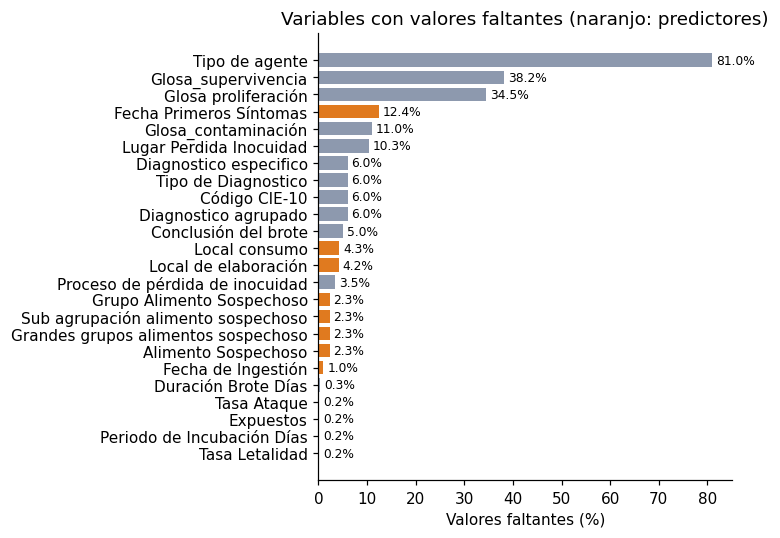

,'Sin definir' / 'Sin identificar'
Sub agrupación alimento sospechoso,343
Grandes grupos alimentos sospechoso,343
Local de elaboración,84
Local consumo,61
Glosa_contaminación,2827
Glosa_supervivencia,3041


In [6]:
faltantes = (df_raw.isna().mean() * 100).round(1).sort_values(ascending=False)
faltantes = faltantes[faltantes > 0]
print(f"Variables completas: {(df_raw.isna().sum() == 0).sum()} de {df_raw.shape[1]}")

fig, ax = plt.subplots(figsize=(7, 5))
colores = [NARANJO if c in GRUPOS["Conocidas al notificar (predictores)"] else GRIS for c in faltantes.index]
ax.barh(faltantes.index[::-1], faltantes.values[::-1], color=colores[::-1])
for i, v in enumerate(faltantes.values[::-1]):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("Valores faltantes (%)")
ax.set_title("Variables con valores faltantes (naranjo: predictores)")
guardar(fig, "fig_faltantes.png")
guardar_tabla(faltantes, "01_faltantes")

# Faltantes "ocultos": textos que indican ausencia de información
sin_definir = {c: int(df_raw[c].astype(str).str.strip().str.lower().isin(["sin definir", "sin identificar"]).sum())
               for c in cat_cols}
pd.Series({k: v for k, v in sin_definir.items() if v > 0}, name="'Sin definir' / 'Sin identificar'")

## 4. Correctitud (consistencia lógica)

In [7]:
d = df_raw
retraso = (d["Fecha de notificación"] - d["Fecha de Ingestión"]).dt.days      # días entre ingestión y notificación
chequeos = {
    "Identificador de brote repetido": d["N° Brote ETA"].duplicated(keep=False).sum(),
    "Fecha de ingestión anterior a 2010 (valor de relleno)": (d["Fecha de Ingestión"] < "2010-01-01").sum(),
    "Primeros síntomas antes de la ingestión": (d["Fecha Primeros Síntomas"] < d["Fecha de Ingestión"]).sum(),
    "Notificación antes de la ingestión": (retraso < 0).sum(),
    "Notificación más de 60 días después de la ingestión": (retraso > 60).sum(),
    "Período de incubación distinto a (síntomas − ingestión)":
        ((d["Fecha Primeros Síntomas"] - d["Fecha de Ingestión"]).dt.days
         != d["Periodo de Incubación Días"]).where(d["Fecha Primeros Síntomas"].notna()).sum(),
    "Enfermos mayor que expuestos": (d["Enfermos"] > d["Expuestos"]).sum(),
    "Tasa de ataque mayor a 100%": (d["Tasa Ataque"] > 100).sum(),
    "Categorías con distinta escritura (Local consumo)":
        d["Local consumo"].nunique() - d["Local consumo"].str.lower().nunique(),
}
correctitud = pd.DataFrame({"Registros": pd.Series(chequeos).astype(int)})
correctitud["% del total"] = (correctitud["Registros"] / len(d) * 100).round(1)
guardar_tabla(correctitud, "01_correctitud")
correctitud

,Registros,% del total
Identificador de brote repetido,2,0.0
Fecha de ingestión anterior a 2010 (valor de relleno),4,0.0
Primeros síntomas antes de la ingestión,1438,8.5
Notificación antes de la ingestión,477,2.8
Notificación más de 60 días después de la ingestión,15,0.1
Período de incubación distinto a (síntomas − ingestión),1562,9.3
Enfermos mayor que expuestos,49,0.3
Tasa de ataque mayor a 100%,2,0.0
Categorías con distinta escritura (Local consumo),3,0.0


## 5. Valores atípicos (criterio del rango intercuartílico)

In [8]:
def resumen_iqr(s):
    """Cuartiles, límite superior (Q3 + 1,5·IQR) y cantidad de valores atípicos."""
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    lim_sup = q3 + 1.5 * (q3 - q1)
    return pd.Series({"Q1": q1, "Mediana": s.median(), "Q3": q3, "Límite superior": lim_sup,
                      "Máximo": s.max(), "Atípicos": int((s > lim_sup).sum()),
                      "% atípicos": round((s > lim_sup).mean() * 100, 1)})

vars_out = {"Período de incubación (días)": d["Periodo de Incubación Días"],
            "Retraso de notificación (días)": retraso.where(retraso.between(0, 365)),
            "Enfermos": d["Enfermos"], "Expuestos": d["Expuestos"],
            "Duración del brote (días)": d["Duración Brote Días"]}
outliers = pd.DataFrame({k: resumen_iqr(v) for k, v in vars_out.items()}).T
guardar_tabla(outliers, "01_outliers")
outliers

,Q1,Mediana,Q3,Límite superior,Máximo,Atípicos,% atípicos
Período de incubación (días),0.0,1.0,1.0,2.5,65.0,355.0,2.1
Retraso de notificación (días),1.0,2.0,4.0,8.5,227.0,863.0,5.3
Enfermos,2.0,3.0,5.0,9.5,5470.0,1699.0,10.1
Expuestos,3.0,4.0,8.0,15.5,113851.0,2940.0,17.5
Duración del brote (días),0.0,0.0,1.0,2.5,189.0,1666.0,9.9


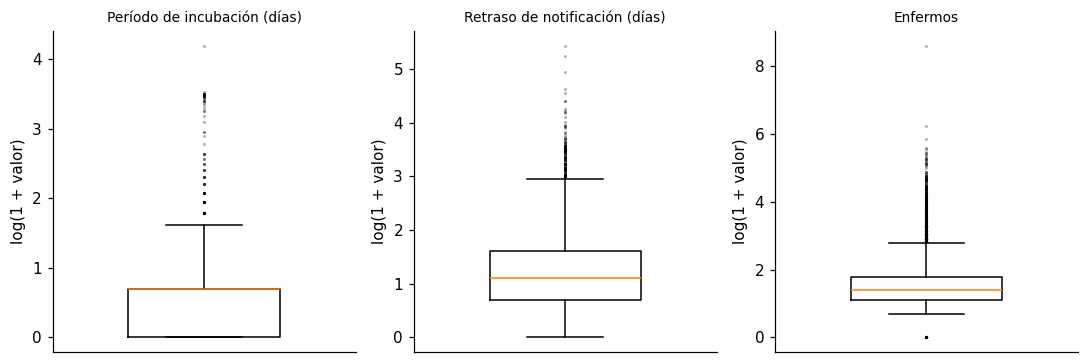

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, (nombre, s) in zip(axes, list(vars_out.items())[:3]):
    ax.boxplot(np.log1p(s.dropna()), widths=.5, flierprops=dict(marker=".", markersize=2, alpha=.3))
    ax.set_title(nombre, fontsize=9)
    ax.set_ylabel("log(1 + valor)")
    ax.set_xticks([])
guardar(fig, "fig_outliers.png")

## 6. Variable objetivo y tendencias

Tipo de Diagnostico     Diagnostico especifico  Diagnostico inespecifico  \
Conclusión del brote                                                       
Otros resultados                            58                       278   
Realizada, en estudio                       23                        40   
Realizada, se confirma                    2956                     11543   
Realizada, se descarta                      35                       216   
Sin conclusión                             129                       562   
Total                                     3201                     12639   

Tipo de Diagnostico     Sin diagnóstico  Total  
Conclusión del brote                            
Otros resultados                     73    409  
Realizada, en estudio                 8     71  
Realizada, se confirma              323  14822  
Realizada, se descarta              458    709  
Sin conclusión                      154    845  
Total                              1016  16856  

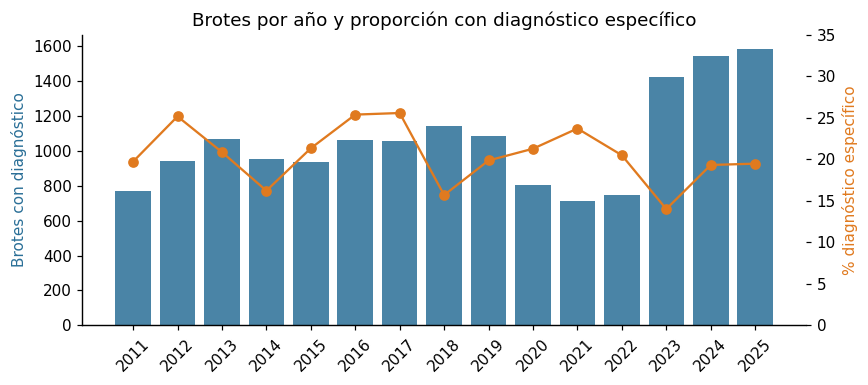

,brotes,pct_especifico
Año estadistico,,
2011,771,19.7
2012,942,25.2
2013,1069,20.9
2014,956,16.2
2015,938,21.3
2016,1064,25.4
2017,1056,25.6
2018,1141,15.7
2019,1088,19.9


In [10]:
conclusion = d["Conclusión del brote"].astype("string").str.strip().fillna("Sin conclusión")
cruce = pd.crosstab(conclusion, d["Tipo de Diagnostico"].fillna("Sin diagnóstico"), margins=True, margins_name="Total")
guardar_tabla(cruce, "01_conclusion_vs_diagnostico")
print(cruce)

base = d[d["Tipo de Diagnostico"].notna()].copy()                         # brotes con diagnóstico registrado
base["y"] = (base["Tipo de Diagnostico"] == "Diagnostico especifico").astype(int)
base["mes"] = base["Fecha de notificación"].dt.month
print(f"\nBrotes con diagnóstico: {len(base)} | específico: {base.y.sum()} ({base.y.mean():.1%})")

por_anio = base.groupby("Año estadistico").agg(brotes=("y", "size"), pct_especifico=("y", "mean"))
fig, ax1 = plt.subplots(figsize=(8, 3.6))
ax1.bar(por_anio.index, por_anio.brotes, color=AZUL, alpha=.85)
ax1.set_ylabel("Brotes con diagnóstico", color=AZUL)
ax2 = ax1.twinx()
ax2.plot(por_anio.index, por_anio.pct_especifico * 100, color=NARANJO, marker="o")
ax2.set_ylabel("% diagnóstico específico", color=NARANJO)
ax2.set_ylim(0, 35)
ax1.set_xticks(por_anio.index)
ax1.tick_params(axis="x", rotation=45)
ax1.set_title("Brotes por año y proporción con diagnóstico específico")
guardar(fig, "fig_anual.png")
guardar_tabla(por_anio, "01_por_anio")
por_anio.assign(pct_especifico=lambda t: (t.pct_especifico * 100).round(1))

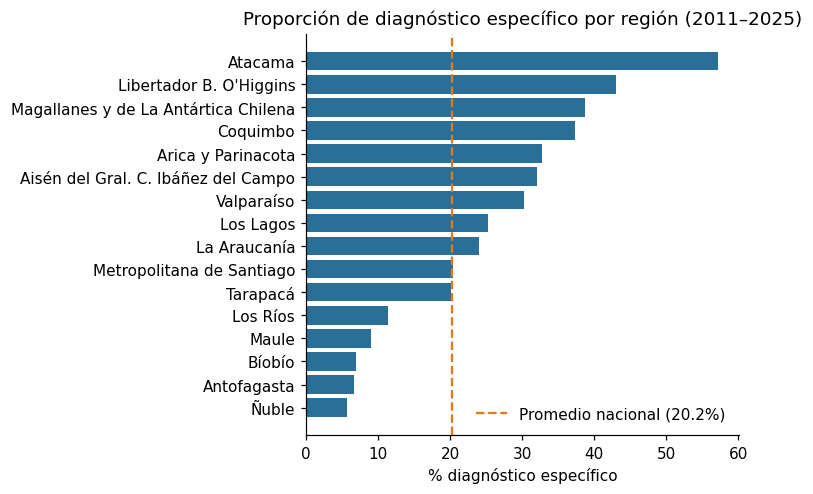

In [11]:
def tasa_por(col, min_n=30):
    """% de diagnóstico específico por categoría (solo categorías con al menos min_n brotes)."""
    t = base.groupby(col)["y"].agg(["size", "mean"]).rename(columns={"size": "brotes", "mean": "pct"})
    return t[t.brotes >= min_n].sort_values("pct")

reg = tasa_por("Región de consumo")
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(reg.index.str.replace("De ", "").str.replace("Del ", ""), reg.pct * 100, color=AZUL)
ax.axvline(base.y.mean() * 100, color=NARANJO, ls="--", label=f"Promedio nacional ({base.y.mean():.1%})")
ax.set_xlabel("% diagnóstico específico")
ax.set_title("Proporción de diagnóstico específico por región (2011–2025)")
ax.legend(loc="lower right", frameon=False)
guardar(fig, "fig_region.png")
guardar_tabla(reg, "01_por_region")

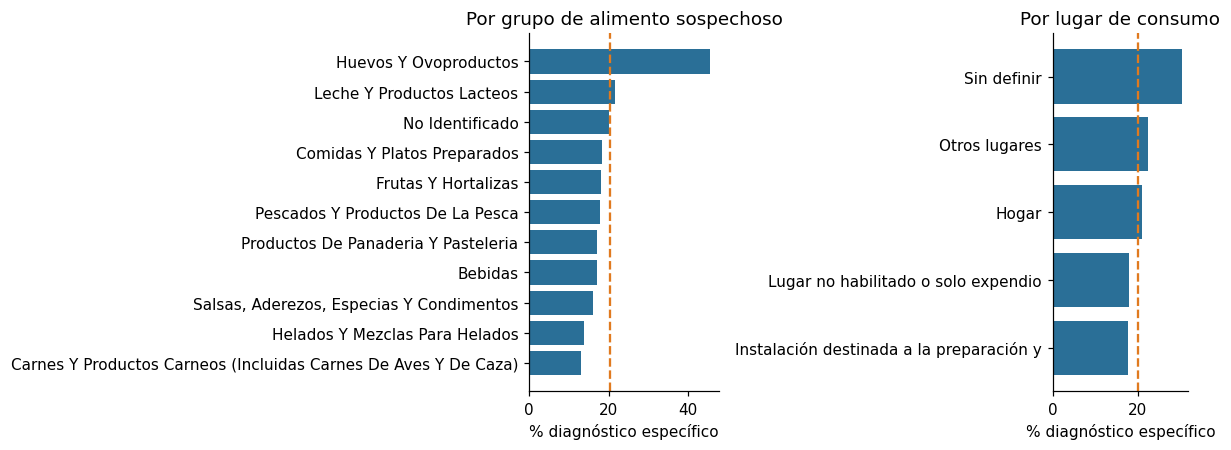

In [12]:
alim = tasa_por("Grupo Alimento Sospechoso", min_n=50)
loc = tasa_por("Local consumo", min_n=50)
loc.index = loc.index.str.capitalize().str.slice(0, 40)
loc = loc.groupby(level=0).agg({"brotes": "sum", "pct": "mean"}).sort_values("pct")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].barh(alim.index, alim.pct * 100, color=AZUL)
axes[0].set_title("Por grupo de alimento sospechoso")
axes[1].barh(loc.index, loc.pct * 100, color=AZUL)
axes[1].set_title("Por lugar de consumo")
for ax in axes:
    ax.axvline(base.y.mean() * 100, color=NARANJO, ls="--")
    ax.set_xlabel("% diagnóstico específico")
guardar(fig, "fig_alimento_lugar.png")

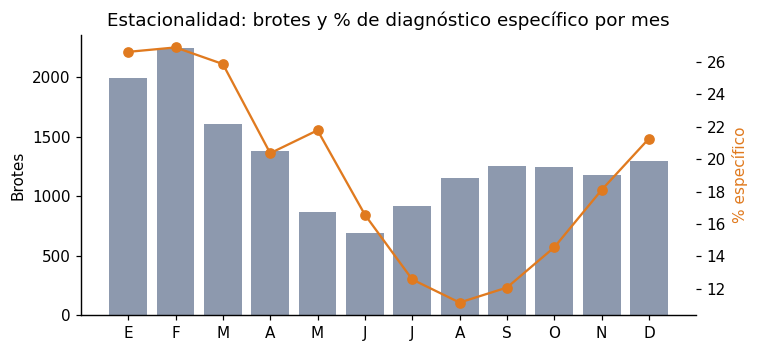

In [13]:
mes = base.groupby("mes")["y"].agg(["size", "mean"])
fig, ax1 = plt.subplots(figsize=(7, 3.3))
ax1.bar(mes.index, mes["size"], color=GRIS)
ax1.set_ylabel("Brotes")
ax2 = ax1.twinx()
ax2.plot(mes.index, mes["mean"] * 100, color=NARANJO, marker="o")
ax2.set_ylabel("% específico", color=NARANJO)
ax1.set_xticks(range(1, 13), ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax1.set_title("Estacionalidad: brotes y % de diagnóstico específico por mes")
guardar(fig, "fig_mes.png")

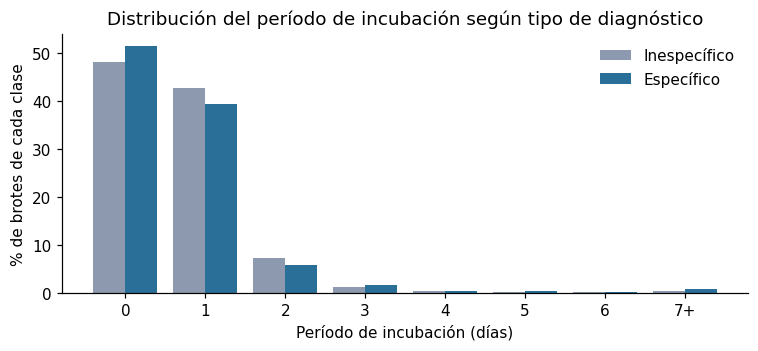

In [14]:
inc = base["Periodo de Incubación Días"].clip(upper=7)
tab_inc = pd.crosstab(inc, base.y, normalize="columns") * 100       # % dentro de cada clase
fig, ax = plt.subplots(figsize=(7, 3.3))
w = .4
ax.bar(tab_inc.index - w / 2, tab_inc[0], w, color=GRIS, label="Inespecífico")
ax.bar(tab_inc.index + w / 2, tab_inc[1], w, color=AZUL, label="Específico")
ax.set_xticks(range(8), [str(i) for i in range(7)] + ["7+"])
ax.set_xlabel("Período de incubación (días)")
ax.set_ylabel("% de brotes de cada clase")
ax.legend(frameon=False)
ax.set_title("Distribución del período de incubación según tipo de diagnóstico")
guardar(fig, "fig_incubacion.png")

## 7. Asociación de los predictores con el diagnóstico
Chi-cuadrado y **V de Cramér** (0 = sin asociación, 1 = perfecta) para categóricas; Mann-Whitney para la incubación.

In [15]:
def cramer_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(tabla)
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1))), p

asoc = []
for c in ["Región de consumo", "comuna de consumo", "Local de elaboración", "Local consumo",
          "Grupo Alimento Sospechoso", "Alimento Sospechoso", "Sub agrupación alimento sospechoso",
          "Grandes grupos alimentos sospechoso", "mes"]:
    v, p = cramer_v(base[c].fillna("Faltante"), base.y)
    asoc.append({"Variable": c, "Prueba": "Chi-cuadrado", "V de Cramér": round(v, 3), "valor p": p})
a = base.loc[base.y == 1, "Periodo de Incubación Días"].dropna()
b = base.loc[base.y == 0, "Periodo de Incubación Días"].dropna()
u, p = stats.mannwhitneyu(a, b)
asoc.append({"Variable": "Periodo de Incubación Días", "Prueba": "Mann-Whitney", "V de Cramér": np.nan, "valor p": p})
asociacion = pd.DataFrame(asoc).sort_values("V de Cramér", ascending=False)
guardar_tabla(asociacion, "01_asociacion")
asociacion

,Variable,Prueba,V de Cramér,valor p
1,comuna de consumo,Chi-cuadrado,0.376,9.851492e-276
0,Región de consumo,Chi-cuadrado,0.323,0.000000e+00
5,Alimento Sospechoso,Chi-cuadrado,0.294,2.802883e-210
6,Sub agrupación alimento sospechoso,Chi-cuadrado,0.257,5.869885e-205
4,Grupo Alimento Sospechoso,Chi-cuadrado,0.206,6.735393e-131
8,mes,Chi-cuadrado,0.143,9.188993e-63
7,Grandes grupos alimentos sospechoso,Chi-cuadrado,0.106,4.827510e-36
2,Local de elaboración,Chi-cuadrado,0.091,1.950180e-26
3,Local consumo,Chi-cuadrado,0.082,2.638655e-19
9,Periodo de Incubación Días,Mann-Whitney,NaN,3.708600e-03


## 8. Preparación y partición temporal
Limpieza, construcción de variables y partición (funciones en `src/datos.py`): entrenamiento 2012–2020, validación 2021–2022 y prueba 2023–2025.

In [16]:
datos = D.preparar(df_raw)                    # población: brotes confirmados con diagnóstico
p = D.particionar(datos)
dist = D.resumen_particion(p["datos"])
guardar_tabla(dist, "01_particion")
print(datos.shape, "| categorías de comuna:", p["datos"]["comuna de consumo"].nunique(),
      "| alimento:", p["datos"]["Alimento Sospechoso"].nunique())
dist

(14244, 48) | categorías de comuna: 125 | alimento: 47


,años,brotes,específicos,prevalencia,% del total
conjunto,,,,,
Entrenamiento,2012–2020,8327,1767,21.2,58.5
Validación,2021–2022,1424,317,22.3,10.0
Prueba,2023–2025,4493,797,17.7,31.5


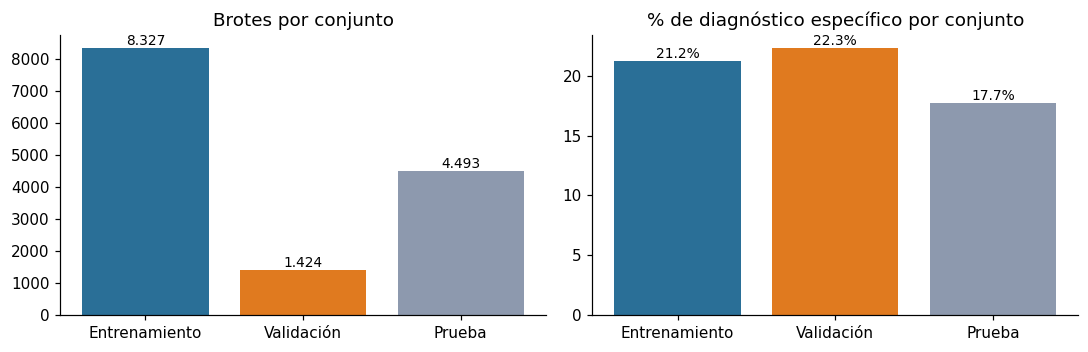

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
colores = [AZUL, NARANJO, GRIS]
axes[0].bar(dist.index, dist.brotes, color=colores)
axes[0].set_title("Brotes por conjunto")
axes[1].bar(dist.index, dist.prevalencia, color=colores)
axes[1].set_title("% de diagnóstico específico por conjunto")
for i, v in enumerate(dist.brotes):
    axes[0].text(i, v, f"{v:,.0f}".replace(",", "."), ha="center", va="bottom", fontsize=9)
for i, v in enumerate(dist.prevalencia):
    axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
guardar(fig, "fig_particion.png")